In [14]:
#Célula 1 — Importar as bibliotecas e carregar a base
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns

# Configuração visual
sns.set_theme(style="whitegrid")

# Dados transcritos da tabela do IBGE
dados = {
    "Estado": [
        "Acre", "Alagoas", "Amapá", "Amazonas", "Bahia",
        "Ceará", "Distrito Federal", "Espírito Santo", "Goiás",
        "Maranhão", "Mato Grosso", "Mato Grosso do Sul",
        "Minas Gerais", "Paraná", "Paraíba", "Pará",
        "Pernambuco", "Piauí", "Rio Grande do Norte",
        "Rio Grande do Sul", "Rio de Janeiro", "Rondônia",
        "Roraima", "Santa Catarina", "Sergipe", "São Paulo",
        "Tocantins"
    ],
    "PIB": [
        26291321, 89688932, 28020120, 161794976, 430987853,
        232239257, 365669108, 209829732, 336746975,
        149227195, 273008586, 184402118, 971977551,
        670919162, 96963174, 254546511, 270474919,
        80916856, 101740275, 650107022, 1172871443,
        76456179, 25124805, 513392973, 60816662,
        3444814033, 64317699
    ]
}

# Criar DataFrame
base_pib = pd.DataFrame(dados)

In [16]:
#1. VISUALIZAR ESTRUTURA DA BASE
print("Dimensões da base:", base_pib.shape)
print("Quantidade de estados:", base_pib["Estado"].nunique())
print("Valores ausentes:", base_pib.isnull().sum().sum())
print("Registros duplicados:", base_pib.duplicated().sum())

display(base_pib.head())

Dimensões da base: (27, 2)
Quantidade de estados: 27
Valores ausentes: 0
Registros duplicados: 0


,Estado,PIB
0,Acre,26291321
1,Alagoas,89688932
2,Amapá,28020120
3,Amazonas,161794976
4,Bahia,430987853


In [18]:
#2. ESTATÍSTICAS DESCRITIVAS

estatisticas = base_pib["PIB"].describe().to_frame()

display(
    estatisticas.style.format(
        "{:,.2f}",
        thousands=".",
        decimal=","
    )
)

,PIB
count,"27,00"
mean,"405.309.090,26"
std,"672.650.116,31"
min,"25.124.805,00"
25%,"85.302.894,00"
50%,"209.829.732,00"
75%,"398.328.480,50"
max,"3.444.814.033,00"


In [19]:
#3. FUNÇÃO DE FORMATAÇÃO BRASILEIRA

def formato_br(valor, casas=2):
    return f"{valor:,.{casas}f}".replace(
        ",", "X"
    ).replace(".", ",").replace("X", ".")


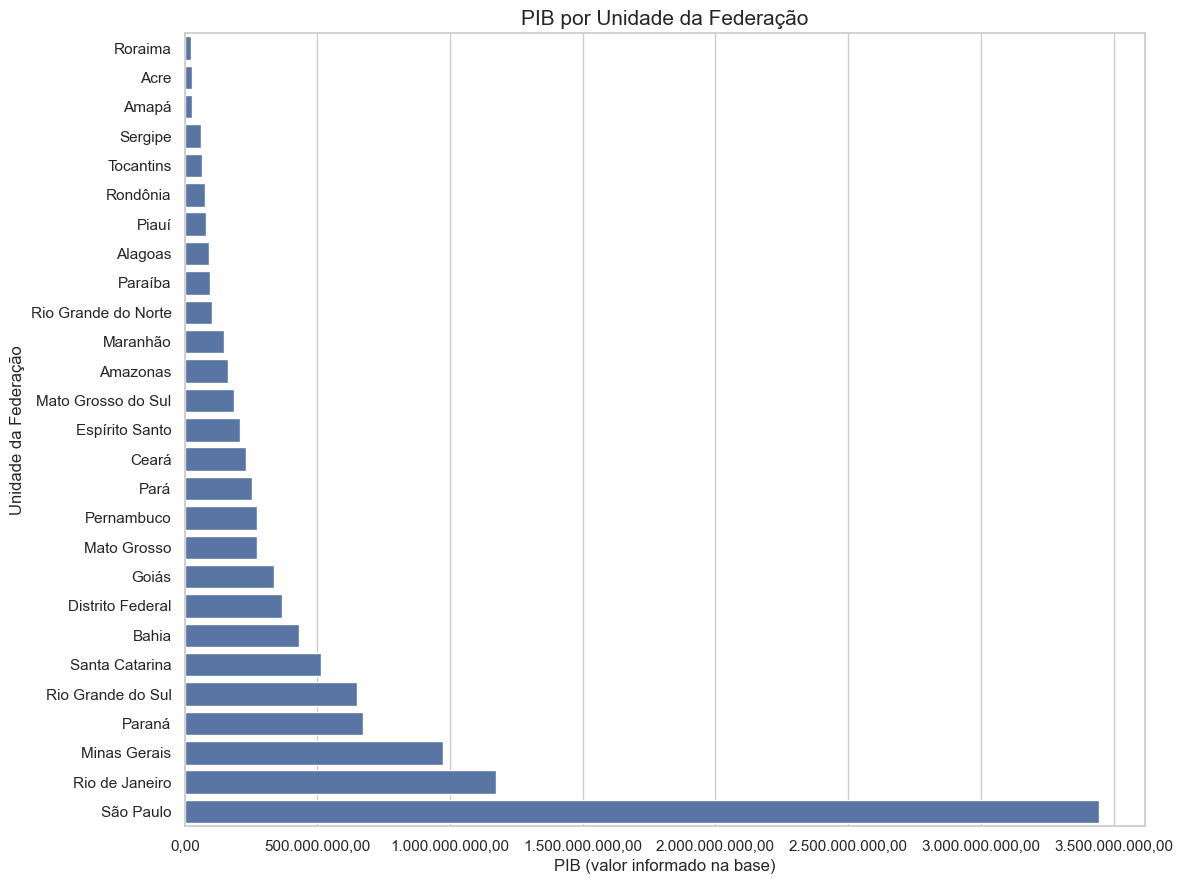

In [20]:
#4. GRÁFICO DE BARRAS: TODOS OS ESTADOS

ordenada = base_pib.sort_values(
    by="PIB",
    ascending=True
)

fig, ax = plt.subplots(figsize=(12, 9))

sns.barplot(
    data=ordenada,
    x="PIB",
    y="Estado",
    ax=ax
)

ax.xaxis.set_major_formatter(
    ticker.FuncFormatter(
        lambda x, pos: formato_br(x, 2)
    )
)

ax.set_title(
    "PIB por Unidade da Federação",
    fontsize=15
)
ax.set_xlabel("PIB (valor informado na base)")
ax.set_ylabel("Unidade da Federação")

plt.tight_layout()
plt.show()

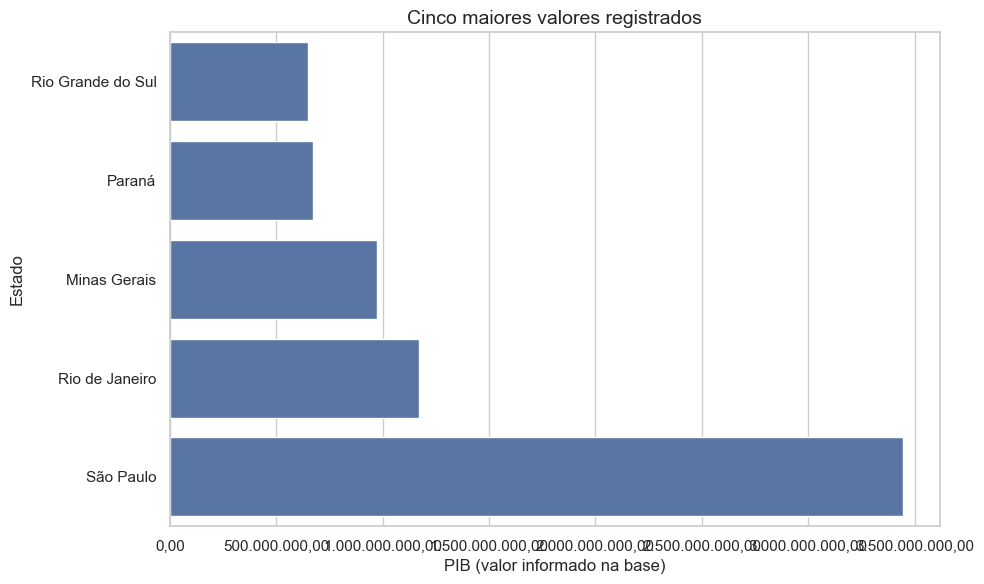

In [22]:
#5. GRÁFICO: CINCO MAIORES VALORES

top5 = base_pib.nlargest(
    5, "PIB"
).sort_values("PIB", ascending=True)

fig, ax = plt.subplots(figsize=(10, 6))

sns.barplot(
    data=top5,
    x="PIB",
    y="Estado",
    ax=ax
)

ax.xaxis.set_major_formatter(
    ticker.FuncFormatter(
        lambda x, pos: formato_br(x, 2)
    )
)

ax.set_title(
    "Cinco maiores valores registrados",
    fontsize=14
)
ax.set_xlabel("PIB (valor informado na base)")
ax.set_ylabel("Estado")

plt.tight_layout()
plt.show()

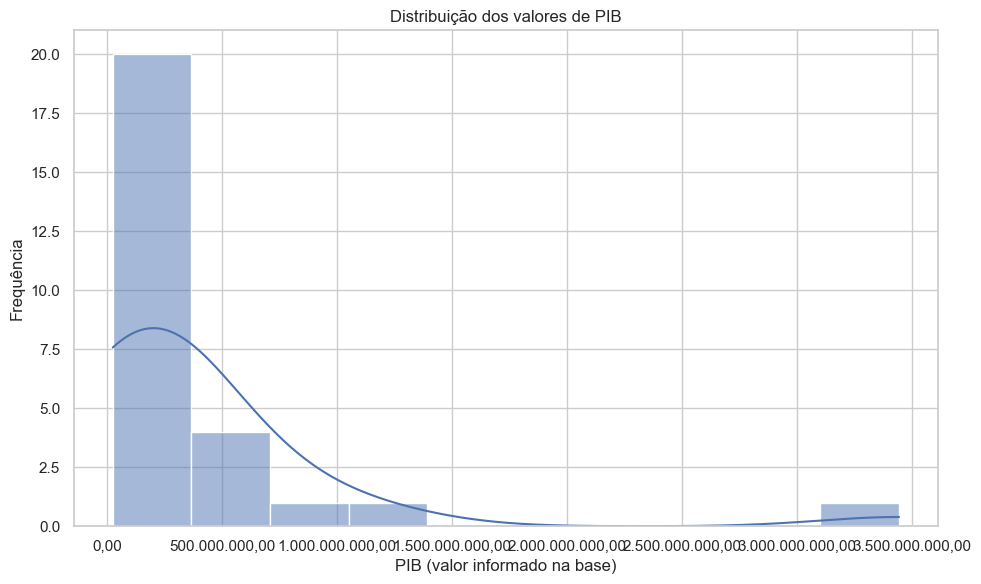

In [24]:
#6. HISTOGRAMA DA DISTRIBUIÇÃO

fig, ax = plt.subplots(figsize=(10, 6))

sns.histplot(
    data=base_pib,
    x="PIB",
    bins=10,
    kde=True,
    ax=ax
)

ax.xaxis.set_major_formatter(
    ticker.FuncFormatter(
        lambda x, pos: formato_br(x, 2)
    )
)

ax.set_title("Distribuição dos valores de PIB")
ax.set_xlabel("PIB (valor informado na base)")
ax.set_ylabel("Frequência")

plt.tight_layout()
plt.show()



In [25]:
# -----------------------------------
# 7. PARTICIPAÇÃO PERCENTUAL
# -----------------------------------

base_pib["Participacao_%"] = (
    base_pib["PIB"] / base_pib["PIB"].sum()
) * 100

participacao = base_pib.sort_values(
    by="Participacao_%",
    ascending=False
)

display(
    participacao.head(10).style.format({
        "PIB": "{:,.2f}",
        "Participacao_%": "{:.2f}%"
    }, thousands=".", decimal=",")
)


,Estado,PIB,Participacao_%
25,São Paulo,"3.444.814.033,00","31,48%"
20,Rio de Janeiro,"1.172.871.443,00","10,72%"
12,Minas Gerais,"971.977.551,00","8,88%"
13,Paraná,"670.919.162,00","6,13%"
19,Rio Grande do Sul,"650.107.022,00","5,94%"
23,Santa Catarina,"513.392.973,00","4,69%"
4,Bahia,"430.987.853,00","3,94%"
6,Distrito Federal,"365.669.108,00","3,34%"
8,Goiás,"336.746.975,00","3,08%"
10,Mato Grosso,"273.008.586,00","2,49%"


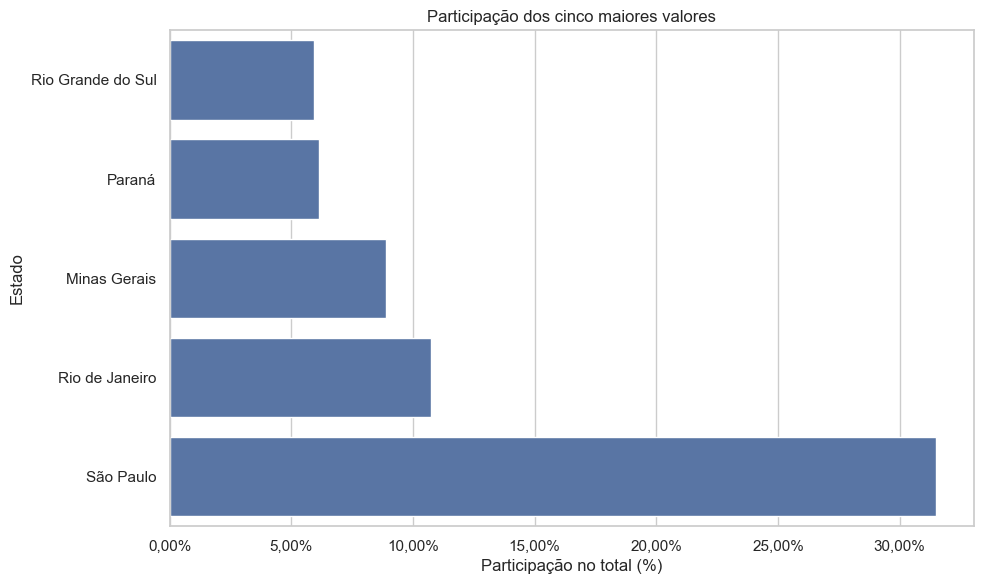

In [26]:
#8. GRÁFICO DE PARTICIPAÇÃO DOS CINCO MAIORES
# -----------------------------------

top5_participacao = participacao.head(5).sort_values(
    "Participacao_%"
)

fig, ax = plt.subplots(figsize=(10, 6))

sns.barplot(
    data=top5_participacao,
    x="Participacao_%",
    y="Estado",
    ax=ax
)

ax.xaxis.set_major_formatter(
    ticker.FuncFormatter(
        lambda x, pos: formato_br(x, 2) + "%"
    )
)

ax.set_title("Participação dos cinco maiores valores")
ax.set_xlabel("Participação no total (%)")
ax.set_ylabel("Estado")

plt.tight_layout()
plt.show()